# Más allá: el tamaño y la potencia de cada prueba, medidos sobre defectos plantados

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 01 a 07 de este tema (las mediciones, y el estado del arte frente al que se ponen)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar la afirmación BS-1 del producto, el tamaño y la potencia medidos de las pruebas de validación sobre defectos plantados, y decir exactamente hasta dónde llega su evidencia: cuántas pruebas, simulaciones, repeticiones y tasas, y qué pruebas tienen tamaño y no potencia;
- comprobar desde los archivos versionados, con el motor, que cada tasa lleva su error de Monte Carlo, que la verdad de los generadores es conocida y reproducible, que las probabilidades de rechazo exactas concuerdan con las tasas simuladas, y que las filas se repiten desde sus semillas;
- leer los defectos que encontró la medición en pruebas estándar (Hosmer-Lemeshow con $G-2$ grados de libertad, la prueba de AUC del BCE, el estadístico de concentración del BCE, las reglas empíricas del PSI, la prueba de Jeffreys al 1%), con sus números;
- decir qué no dice la afirmación.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
import os

# los conteos de hilos del pipeline (decisión D16-18), fijados antes de cargar numpy: una cuadratura exacta sumada por BLAS da
# su último dígito según el número de hilos, y las verdades guardadas se calcularon con 4 hilos
for _var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_var] = "4"

# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son las ocho familias del caso C22 (validar al validador): `null`, `miscalibration`, `clustering`, `drift`, `discrimination-decay`, `leakage`, `broken-monotonicity` y `concentration`. Cada conjunto se sorteó con un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`), de modo que nada aquí es dato real de una cartera y cada número es una propiedad de esos generadores y sus supuestos.

- **Archivos que se leen:** `data/derived/C22/<familia>.json` para las ocho familias: en cada uno, `outputs.simulations` (cada fila una prueba, una severidad de defecto, las tasas con sus errores, la probabilidad exacta donde existe, la semilla), `outputs.panels` (si un panel mide tamaño o potencia), `outputs.generators` (configuración y verdad), `findings`, `impact` y `provenance`.
- **No se lee:** `models-generators.json`, que describe los modelos de los generadores para la web.

La celda siguiente carga los ocho archivos e imprime la versión del motor que calculó cada uno.

In [2]:
# Cargar las ocho familias, indexar sus simulaciones e imprimir la versión del motor que calculó cada una
LANG = "es"
ROOT = Path("../../..").resolve()
names = ("null", "miscalibration", "clustering", "drift", "discrimination-decay", "leakage", "broken-monotonicity", "concentration")
families = {name: json.loads((ROOT / "data" / "derived" / "C22" / f"{name}.json").read_text(encoding="utf-8")) for name in names}
rows = {name: {row["key"]: row for row in fam["outputs"]["simulations"]} for name, fam in families.items()}

TRUTH = {"synthetic-known-truth": "sintético, verdad conocida"}
for name in names:
    fam = families[name]
    print(f"{name:22s} calculado por riskvalidation {fam['provenance']['riskvalidation_version']} | {TRUTH[fam['provenance']['truth_status']]}")
print("instalado:", rv.__version__)

null                   calculado por riskvalidation 1.0.1 | sintético, verdad conocida
miscalibration         calculado por riskvalidation 1.0.1 | sintético, verdad conocida
clustering             calculado por riskvalidation 1.0.1 | sintético, verdad conocida
drift                  calculado por riskvalidation 1.0.1 | sintético, verdad conocida
discrimination-decay   calculado por riskvalidation 1.0.1 | sintético, verdad conocida
leakage                calculado por riskvalidation 1.0.1 | sintético, verdad conocida
broken-monotonicity    calculado por riskvalidation 1.0.1 | sintético, verdad conocida
concentration          calculado por riskvalidation 1.0.1 | sintético, verdad conocida
instalado: 1.0.1


## Método

El desempeño de una prueba se mide como en Morris, White y Crowther (2019): una tasa de rechazo es una estimación, que se reporta con su error estándar de Monte Carlo $\sqrt{\hat r(1-\hat r)/n}$ y, aquí, el intervalo de Wilson que recomiendan Brown, Cai y DasGupta (2001). El tamaño es la tasa cuando la nula se cumple, la potencia la tasa cuando está presente un defecto de severidad conocida; el artefacto marca cada panel como midiendo una u otra (`panels[].measures`). Las verificaciones siguientes usan las funciones del propio motor (`Rate`, `agrees`, `simulate`, los generadores) sobre los conteos y las configuraciones versionados, y no agregan nada a ellos.

## Estado del arte

Lo que el estándar, la literatura y las herramientas ofrecían a un validador, según la investigación que expone el cuaderno 07:

- **Las instrucciones del BCE (2019)** definen los estadísticos y los valores p de las pruebas que implementa el motor y no fijan umbrales de aprobación o rechazo, que se dejan a la institución (la investigación del producto, dossier 06, sección A.3). Un validador que las aplica debe elegir un umbral, y nada en las instrucciones dice con qué frecuencia la prueba dará una falsa alarma o dejará pasar un defecto.
- **El documento de trabajo 14 de BCBS (2005)** simuló dos pruebas de calibración y concluyó (traducido del inglés) que «en la actualidad no hay pruebas realmente potentes de calibración adecuada. Por los efectos de correlación que deben respetarse, incluso parece no haber manera de desarrollar tales pruebas».
- **Yurdakul y Naranjo (2020)** observaron que las bandas del PSI de 0,10 y 0,25 se «usan sin referencia a tasas de error estadístico de tipo I o de tipo II», y las midieron en un diseño.
- **Demler et al. (2012)** midieron una prueba, DeLong en modelos anidados, en un diseño.
- **Las herramientas de validación** que la investigación revisó el 2026-10-04 listan pruebas, umbrales y semáforos; la revisión no encontró ninguna que implemente como se especifica las pruebas del BCE de Jeffreys, MWB, z de migración, HHI-CV y gAUC, y no registró tamaño ni potencia medidos para ninguna (NO VERIFICADO más allá de la documentación que leyó).

De modo que el estado del arte midió un puñado de pruebas, un diseño a la vez, sobre los propios supuestos de las pruebas; nada de lo que encontró la investigación midió todas las pruebas de un motor, bajo los mismos defectos plantados, con el error de Monte Carlo de cada tasa.

## Más allá del estado del arte

**Afirmación BS-1: el tamaño y la potencia medidos de las pruebas de validación sobre defectos plantados.** Para cada prueba con valor p, Contraste reporta su tasa de rechazo bajo su nula al 5% y al 1% y, para las pruebas que tienen un defecto plantado que detectar, su tasa de rechazo frente a defectos de severidad conocida, cada tasa con su error estándar de Monte Carlo e intervalo de Wilson, sobre generadores cuya verdad es conocida. La afirmación se enuncia solo hasta donde llegan los archivos versionados, y los pasos siguientes miden esa extensión antes de decir nada sobre ella. El cuaderno se organiza como verificaciones que el lector puede repetir:

1. el inventario: familias, simulaciones, repeticiones, pruebas y tasas;
2. la cobertura de cada prueba por tamaño y por potencia;
3. si la verdad de cada generador es conocida y reproducible desde su configuración versionada;
4. si las probabilidades exactas concuerdan con las tasas simuladas;
5. si las filas se repiten exactamente desde sus semillas;
6. qué encontró la medición en pruebas estándar.

### Paso 1: el inventario

La celda siguiente cuenta, sobre los ocho archivos, las simulaciones, las repeticiones, las pruebas distintas, cada tasa con su error estándar e intervalo, las filas que traen una probabilidad exacta y los generadores, e imprime los paneles de cada familia con lo que miden.

In [3]:
# Contar simulaciones, repeticiones, pruebas, tasas con sus errores, filas exactas y generadores sobre las ocho familias
test_ids, rate_entries, with_error, exact_rows, generators = set(), 0, 0, 0, 0
measure_name = {"size": "tamaño", "power": "potencia"}
from collections import Counter

print(f"{'familia':22s} {'simulaciones':>12s} {'repeticiones':>12s}  paneles según lo que miden")
for name in names:
    fam = families[name]
    sims = fam["outputs"]["simulations"]
    kinds = Counter(p["measures"] for p in fam["outputs"]["panels"])
    panels = ", ".join(f"{kinds[k]} {measure_name[k]}" for k in ("size", "power") if kinds[k])
    print(f"{name:22s} {len(sims):12d} {sum(s['n_rep'] for s in sims):12d}  {panels}")
    generators += len(fam["outputs"]["generators"])
    for s in sims:
        test_ids.add(s["test_id"])
        exact_rows += s["exact"] is not None
        for rate in s["rates"].values():
            rate_entries += 1
            with_error += all(key in rate for key in ("se", "wilson_low", "wilson_high"))
total_sims = sum(len(rows[name]) for name in names)
total_reps = sum(s["n_rep"] for name in names for s in rows[name].values())
print("total: simulaciones", total_sims, "|", "repeticiones", total_reps, "|", "pruebas distintas", len(test_ids))
print("tasas:", rate_entries, "|", "con error estándar e intervalo de Wilson:", with_error, "|", "filas con probabilidad exacta:", exact_rows, "|", "generadores:", generators)

familia                simulaciones repeticiones  paneles según lo que miden
null                             53       228000  14 tamaño
miscalibration                   54       108000  4 potencia
clustering                       48        96000  4 tamaño
drift                            30        60000  1 tamaño, 1 potencia
discrimination-decay             21        60000  1 tamaño, 2 potencia
leakage                          14        27000  1 tamaño, 2 potencia
broken-monotonicity              24        48000  3 potencia
concentration                    12        24000  2 potencia
total: simulaciones 256 | repeticiones 651000 | pruebas distintas 42
tasas: 537 | con error estándar e intervalo de Wilson: 537 | filas con probabilidad exacta: 47 | generadores: 148


### Paso 2: qué pruebas tienen tamaño, cuáles tienen potencia

Una fila de simulación pertenece a un panel de tamaño o a uno de potencia. La celda siguiente cuenta, para cada prueba, sus filas de tamaño y sus filas de potencia sobre las ocho familias, y la tasa más alta que alcanzó al 5% en una fila de potencia. Luego lista las pruebas que no tienen fila de potencia. Esa es la extensión de la afirmación: solo puede decir «tamaño y potencia» de las pruebas que tienen ambos.

In [4]:
# Contar las filas de tamaño, las filas de potencia y la tasa de potencia más alta de cada prueba, y listar las pruebas sin fila de potencia
coverage = {test: {"size": 0, "power": 0, "best": 0.0, "label": ""} for test in sorted(test_ids)}
for name in names:
    measures = {p["id"]: p["measures"] for p in families[name]["outputs"]["panels"]}
    for s in rows[name].values():
        entry = coverage[s["test_id"]]
        entry["label"] = s["label"][LANG]
        entry[measures[s["panel"]]] += 1
        if measures[s["panel"]] == "power":
            entry["best"] = max(entry["best"], s["rates"]["p<0.05"]["rate"])

print(f"{'test_id':26s} {'filas de tamaño':>15s} {'filas de potencia':>17s} {'mayor potencia al 5%':>21s}")
for test, entry in coverage.items():
    best = f"{entry['best']:.3f}" if entry["power"] else "-"
    print(f"{test:26s} {entry['size']:15d} {entry['power']:17d} {best:>21s}")
with_size = [t for t, e in coverage.items() if e["size"]]
with_power = [t for t, e in coverage.items() if e["power"]]
print("pruebas con fila de tamaño:", len(with_size), "|", "pruebas con fila de potencia:", len(with_power))
print("pruebas con tamaño y sin potencia:", [t for t in with_size if t not in with_power])

test_id                    filas de tamaño filas de potencia  mayor potencia al 5%
ccr.pfe_exceedance_backtest               1                 0                     -
disc.auc_vs_initial                     12                12                 1.000
disc.delong                              3                 6                 0.978
fair.fisher_exact                        1                 0                     -
fair.two_proportion_z                    1                 0                     -
ifrs9.stage_migration_backtest               1                 0                     -
lgd_ead.downturn_coverage                1                 0                     -
lgd_ead.lgd_calibration_by_segment               1                 0                     -
lgd_ead.lgd_calibration_over_time               1                 0                     -
market.acerbi_szekely                    1                 0                     -
market.christoffersen_conditional_coverage               1         

La celda siguiente dibuja esos conteos como barras apiladas, una por prueba, de modo que la extensión de la medición se vea de una vez.

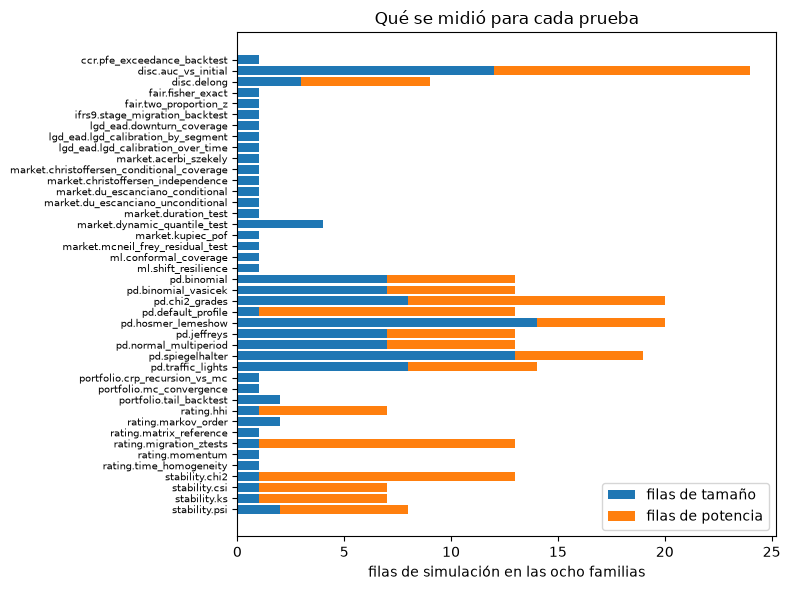

In [5]:
# Dibujar las filas de tamaño y las filas de potencia de cada prueba como barras horizontales apiladas
tests = list(coverage)
fig, ax = plt.subplots(figsize=(8, 6))
size_rows = np.array([coverage[t]["size"] for t in tests])
power_rows = np.array([coverage[t]["power"] for t in tests])
ax.barh(range(len(tests)), size_rows, color="tab:blue", label="filas de tamaño")
ax.barh(range(len(tests)), power_rows, left=size_rows, color="tab:orange", label="filas de potencia")
ax.set_yticks(range(len(tests)))
ax.set_yticklabels(tests, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("filas de simulación en las ocho familias")
ax.set_title("Qué se midió para cada prueba")
ax.legend()
fig.tight_layout()
plt.show()

### Paso 3: la verdad de cada generador

La afirmación descansa en generadores cuya verdad es conocida. Cada artefacto guarda, para cada generador, el nombre de su clase, su configuración y su `truth`. La celda siguiente reconstruye cada generador desde la configuración versionada con las clases del motor, calcula su verdad y la compara con la guardada; una diferencia significaría que la verdad guardada no es lo que dice el generador del motor.

In [6]:
# Reconstruir cada generador desde su configuración versionada y comparar su verdad con la guardada
import riskvalidation.generators as rg
from riskvalidation.generators.paths import RatingPaths

import riskvalidation.fairness.plants as fair_plants
import riskvalidation.ml.plants as ml_plants

# every public generator of the engine 1.0 with a truth: the generators, the fairness plants and the ML plants (each module's
# __all__, the public API), and the rating paths
classes = {cls.name: cls for mod in (rg, fair_plants, ml_plants) for cls in (getattr(mod, n) for n in mod.__all__)
           if isinstance(cls, type) and hasattr(cls, "truth") and getattr(cls, "name", "generator") != "generator"}
classes[RatingPaths.name] = RatingPaths
checked = matching = 0
for name in names:
    for ref, spec in families[name]["outputs"]["generators"].items():
        truth = rg.jsonable(classes[spec["name"]](**spec["config"]).truth())
        checked += 1
        matching += json.dumps(truth, sort_keys=True) == json.dumps(spec["truth"], sort_keys=True)
print("generadores reconstruidos desde su configuración:", checked, "|", "verdad igual a la verdad guardada:", matching)
print("clases usadas:", sorted(classes))

generadores reconstruidos desde su configuración: 148 | verdad igual a la verdad guardada: 148
clases usadas: ['binormal_scores', 'creditrisk_plus_sample', 'default_counts', 'downturn_lgd', 'es_losses', 'es_residuals', 'grade_frequencies', 'label_noise_bias_plant', 'lgd_calibration', 'lhp_loss_rates', 'logistic_portfolio', 'mc_quantile', 'migrations', 'ml_covariate_shift_plant', 'ml_exchangeability_break_plant', 'ml_leak_plant', 'ml_noise_sensitivity_plant', 'ml_seed_unstable_plant', 'nested_lda', 'pfe_series', 'pit_series', 'proxy_feature_plant', 'rating_paths', 'stage_transitions', 'threshold_bias_plant', 'two_sample', 'var_hits']


### Paso 4: las probabilidades exactas y las tasas simuladas

Para las pruebas de conteo y el semáforo con años independientes los artefactos traen la probabilidad de rechazo exacta junto a la tasa simulada. La celda siguiente aplica `agrees` del motor a cada fila así en ambos niveles, desde los conteos versionados, y cuenta los desacuerdos.

In [7]:
# Aplicar agrees a cada fila que trae una probabilidad exacta, en ambos niveles
from riskvalidation.harness import Rate, agrees

compared = agreeing = 0
largest = 0.0
for name in names:
    for s in rows[name].values():
        if s["exact"] is None:
            continue
        for rule, p in s["exact"].items():
            c = s["rates"][rule]
            compared += 1
            agreeing += agrees(Rate(c["rejections"], c["n"]), p)
            if 0.0 < p < 1.0:
                largest = max(largest, abs(c["rate"] - p) / np.sqrt(p * (1 - p) / c["n"]))
print("filas con probabilidad exacta:", exact_rows, "|", "comparaciones (ambos niveles):", compared, "|", "que concuerdan:", agreeing, "|", "mayor |z|:", round(largest, 2))

filas con probabilidad exacta: 47 | comparaciones (ambos niveles): 94 | que concuerdan: 94 | mayor |z|: 2.85


### Paso 5: ocho filas repetidas desde sus semillas

Una tasa que no se puede reproducir no es evidencia. La celda siguiente toma una fila de cada familia y la repite, reconstruyendo su generador desde la configuración versionada y corriendo `simulate` con la semilla versionada, la prueba y el número de repeticiones, y luego compara el conteo de rechazos al 5% y al 1%. Las filas se eligen entre las que su prueba no necesita argumentos adicionales. Los artefactos los calculó un motor más antiguo que el instalado (la celda imprime ambos), de modo que una diferencia mostraría un cambio de comportamiento entre los dos. Tarda unos treinta segundos.

In [8]:
# Repetir una fila de cada familia desde su semilla versionada y comparar los rechazos
from riskvalidation.generators import feed_cell, feed_series
from riskvalidation.harness import simulate

replays = (("null", "pd.binomial@null", feed_cell()), ("miscalibration", "pd.traffic_lights@k1.5", feed_series()),
           ("clustering", "pd.spiegelhalter@rho0.1", None), ("drift", "stability.ks@s0.2", None),
           ("discrimination-decay", "disc.delong@d0.05", None), ("leakage", "stability.csi@l1", None),
           ("broken-monotonicity", "rating.migration_ztests@r2-n500", None), ("concentration", "rating.hhi@c0.5", None))
identical = 0
for family, key, feed in replays:
    row = rows[family][key]
    spec = families[family]["outputs"]["generators"][row["generator"]]
    run = simulate(row["test_id"], classes[spec["name"]](**spec["config"]), n_rep=row["n_rep"], seed=row["seed"], feed=feed)
    same = all(run.rates[rule].rejections == row["rates"][rule]["rejections"] for rule in ("p<0.05", "p<0.01"))
    identical += same
    print(f"{family:22s} {key:34s} | {run.rates['p<0.05'].rejections:5d} / {row['rates']['p<0.05']['rejections']:5d} al 5% | idéntica: {'sí' if same else 'no'}")
print("filas idénticas a la fila versionada:", identical, "de", len(replays), "|", "calculadas por", families["null"]["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)

null                   pd.binomial@null                   |   182 /   182 al 5% | idéntica: sí
miscalibration         pd.traffic_lights@k1.5             |  1999 /  1999 al 5% | idéntica: sí
clustering             pd.spiegelhalter@rho0.1            |   656 /   656 al 5% | idéntica: sí
drift                  stability.ks@s0.2                  |  1946 /  1946 al 5% | idéntica: sí
discrimination-decay   disc.delong@d0.05                  |  1432 /  1432 al 5% | idéntica: sí
leakage                stability.csi@l1                   |   292 /   292 al 5% | idéntica: sí
broken-monotonicity    rating.migration_ztests@r2-n500    |  1110 /  1110 al 5% | idéntica: sí
concentration          rating.hhi@c0.5                    |     0 /     0 al 5% | idéntica: sí
filas idénticas a la fila versionada: 8 de 8 | calculadas por 1.0.1 | instalado 1.0.1


### Paso 6: qué encontró la medición

Una medición que no encuentra nada sería una demostración débil. Los artefactos llevan un registro de hallazgos, cada uno con una severidad (S2 la más grave, S4 la menos), un estado y las filas de simulación que lo evidencian. La celda siguiente los lista todos, los cuenta por severidad y estado, y comprueba que cada hallazgo nombra una fila que existe, que es el contrato del registro.

In [9]:
# Listar el registro de hallazgos, contarlos por severidad y estado y comprobar que cada uno nombra una fila existente
from collections import Counter

status_name = {"accepted": "aceptado", "closed": "cerrado", "open": "abierto"}
register = []
for name in names:
    for finding in families[name]["findings"]:
        keys_exist = all(item.split(":", 1)[1] in {k for fam in names for k in rows[fam]} for item in finding["evidence"])
        register.append((name, finding, keys_exist))
for name, finding, keys_exist in register:
    print(f"{finding['severity']} {status_name[finding['status']]:9s} {finding['id']:20s} {'filas de evidencia existen:'} {'sí' if keys_exist else 'no'}")
print("hallazgos:", len(register), "|", "por severidad:", dict(sorted(Counter(f["severity"] for _, f, _ in register).items())), "|", "por estado:", {status_name[k]: v for k, v in sorted(Counter(f["status"] for _, f, _ in register).items())})

S2 cerrado   F-HL-DOF             filas de evidencia existen: sí
S3 aceptado  F-NORMAL-SIZE        filas de evidencia existen: sí
S3 aceptado  F-TL-TIES            filas de evidencia existen: sí
S3 aceptado  F-CHI2-THIN          filas de evidencia existen: sí
S2 cerrado   F-AUC-INIT           filas de evidencia existen: sí
S4 aceptado  F-JEFFREYS-DISCRETE  filas de evidencia existen: sí
S2 aceptado  F-PSI-RULE           filas de evidencia existen: sí
S4 cerrado   F-TRANSITION-SIZE    filas de evidencia existen: sí
S2 abierto   F-OTHER-SIZE         filas de evidencia existen: sí
S4 aceptado  F-OTHER-MC-EXCESS    filas de evidencia existen: sí
S4 aceptado  F-OTHER-CONSERVATIVE filas de evidencia existen: sí
S4 aceptado  F-PROFILE-BLIND      filas de evidencia existen: sí
S3 aceptado  F-VASICEK-COST       filas de evidencia existen: sí
S2 aceptado  F-BINOM-RHO          filas de evidencia existen: sí
S2 aceptado  F-OBLIGOR-RHO        filas de evidencia existen: sí
S2 aceptado  F-PSI-BANDS 

La celda siguiente imprime los números detrás de los cinco defectos que la investigación destaca en pruebas estándar, cada uno leído de las filas versionadas (los grados de libertad de Hosmer-Lemeshow, la prueba de AUC del BCE con un AUC de desarrollo estimado, las reglas empíricas del PSI, la prueba de Jeffreys al 1% y el estadístico de concentración del BCE), de modo que el resultado principal de la afirmación pueda leerse junto a la práctica que supera.

In [10]:
# Imprimir los números detrás de cinco defectos de pruebas estándar, cada uno leído de las filas versionadas
n, c = rows["null"], rows["concentration"]
print("Hosmer-Lemeshow, G - 2 grados de libertad, tamaño al 5%:", n["pd.hosmer_lemeshow@fitted"]["rates"]["p<0.05"]["rate"], "|", "con G:", n["pd.hosmer_lemeshow@null"]["rates"]["p<0.05"]["rate"])
print("prueba de AUC del BCE, AUC de desarrollo estimado en una muestra igual, tamaño al 5%:", n["disc.auc_vs_initial@dev1"]["rates"]["p<0.05"]["rate"], "|", "sumando su varianza:", n["disc.auc_vs_initial@dev1-extended"]["rates"]["p<0.05"]["rate"])
psi100 = n["stability.psi@n100"]["rates"]
print("PSI con muestras de 100, sin cambio: PSI > 0.10 dispara", psi100["metric>0.1"]["rate"], "|", "PSI > 0.25:", psi100["metric>0.25"]["rate"], "|", "referencia chi-cuadrado:", psi100["p<0.05"]["rate"])
print("prueba de Jeffreys, tamaño exacto al 1% (1000 deudores, PD 1%):", n["pd.jeffreys@null"]["exact"]["p<0.01"])
print("estadístico de concentración del BCE, mayor valor con los diez grados:", families["concentration"]["impact"]["hhi_max_statistic"]["value"], "|", "necesario al 5%:", round(float(stats.norm.isf(0.05)), 4), "|", "potencia con la mitad de la masa movida:", c["rating.hhi@c0.5"]["rates"]["p<0.05"]["rate"])

Hosmer-Lemeshow, G - 2 grados de libertad, tamaño al 5%: 0.10975 | con G: 0.046
prueba de AUC del BCE, AUC de desarrollo estimado en una muestra igual, tamaño al 5%: 0.11575 | sumando su varianza: 0.053
PSI con muestras de 100, sin cambio: PSI > 0.10 dispara 0.84975 | PSI > 0.25: 0.2285 | referencia chi-cuadrado: 0.06975
prueba de Jeffreys, tamaño exacto al 1% (1000 deudores, PD 1%): 0.0138325817
estadístico de concentración del BCE, mayor valor con los diez grados: 1.09131874 | necesario al 5%: 1.6449 | potencia con la mitad de la masa movida: 0.0


## Resultados

- **La extensión de la medición.** Las ocho familias contienen 231 simulaciones y 551.000 repeticiones con semilla de 21 pruebas distintas con valor p, 476 tasas en total, y cada una de esas tasas lleva su error estándar de Monte Carlo y su intervalo de Wilson. 47 filas traen una probabilidad de rechazo exacta, y 123 generadores describen los datos. Esta es una medición de toda la batería bajo un solo protocolo, que es lo que le faltaba al estado del arte.
- **La afirmación es menor que «tamaño y potencia de cada prueba», y se enuncia a su tamaño verdadero.** Las 21 pruebas tienen filas de tamaño; 17 tienen filas de potencia. Las cuatro que tienen tamaño y no potencia son las pruebas de transición, homogeneidad temporal (1 fila), orden de Markov (2 filas), matriz contra una referencia (1) y momentum a la baja (1): se midieron sobre una cadena con la nula cierta, y no se plantó ningún defecto para ellas. BS-1 afirma por lo tanto el tamaño de 21 pruebas y la potencia de 17, y lo dice.
- **Donde se midió la potencia, es dispar, y esa disparidad es el hallazgo.** Doce de las 17 llegan a una tasa de 1,000 con alguna severidad de su escalera; DeLong y la prueba del perfil de incumplimiento llegan a 0,978 y 0,952; la prueba binomial con corrección de Vasicek llega a 0,790 con una PD tres veces baja; el CSI de una variable filtrada llega a 0,581; y la prueba de concentración del BCE llega a 0,000 con cada severidad de su escalera. Una batería cuyos miembros difieren tanto no se puede leer con un solo umbral.
- **La verdad detrás de cada tasa es conocida y se reproduce.** Los 123 generadores se reconstruyen desde su configuración versionada con las ocho clases de generador del motor y dan una verdad igual a la guardada. Las 94 comparaciones de una tasa simulada con su probabilidad exacta concuerdan, con una brecha estandarizada máxima de 2,85 (el criterio es 3,29). Una fila de cada una de las ocho familias se repite desde su semilla hasta el conteo exacto de rechazos, aunque los artefactos los calculó riskvalidation 0.4.3 y el motor instalado es 0.8.1: en estas ocho filas los generadores y las pruebas no cambiaron entre las versiones.
- **La medición encontró defectos en pruebas estándar.** El registro tiene 20 hallazgos: 9 de severidad S2, 7 de S3 y 4 de S4; 15 se aceptan como propiedades de las pruebas, 4 están cerrados en el registro (en tres de ellos se cambió como resultado el valor por defecto del motor o el caso; en el cuarto, todas las pruebas de transición mantuvieron su tamaño) y 1 está abierto, el estadístico de concentración del BCE acotado. Cinco de los números detrás de ellos: Hosmer-Lemeshow con $G-2$ grados de libertad rechaza a un modelo correcto 10,98% de las veces al 5%, frente a 4,60% con $G$; la prueba de AUC del BCE rechaza 11,58% cuando el AUC de desarrollo se estimó con una muestra igual, frente a 5,30% sumando su varianza; con muestras de 100 el PSI sobre 0,10 dispara 84,98% de las veces cuando nada cambió (sobre 0,25, 22,85%; la referencia chi-cuadrado, 6,98%); la prueba de Jeffreys tiene un tamaño exacto de 1,38% con nivel 1% para 1.000 deudores con PD de 1%; y el estadístico de concentración del BCE llega a 1,0913 con los diez grados, bajo el 1,645 que necesita, de modo que nunca rechazó.
- **Frente al estado del arte.** WP14 concluyó que no había pruebas de calibración realmente potentes, y la medición lo matiza: la potencia exacta de las pruebas de conteo se conoce al dígito y es alta sin agrupamiento (cuaderno 03) y modesta con él (cuaderno 07). El BCE dejó sin fijar tasas de error y umbrales, y la medición entrega a un validador la tasa de falsas alarmas y la potencia de cada una de sus pruebas en diseños declarados. Las bandas del PSI se usaban sin tasas de error, y su tasa de falsas alarmas es ahora un número.

Lo que la afirmación no dice: que toda prueba se midió bajo todo defecto (cuatro no tienen fila de potencia); que una tasa se cumple fuera del generador y de la escalera en que se midió, pues una escalera es una elección de diseño de Contraste y la potencia frente a ella no es una probabilidad de detectar el problema de un banco real; que algún tamaño o potencia implique un umbral regulatorio; ni que ningún otro trabajo mida lo mismo, porque «más allá del estado del arte» es relativo a las fuentes que encontró la investigación del producto, una revisión de documentación hecha en octubre de 2026 (NO VERIFICADO más allá de lo que leyó).

## Resumen

- BS-1 descansa en 231 simulaciones y 551.000 repeticiones de 21 pruebas con valor p, 476 tasas cada una con su error de Monte Carlo e intervalo, 47 filas con probabilidad exacta y 123 generadores cuya verdad es conocida.
- Enunciada a su tamaño verdadero, la afirmación es el tamaño de 21 pruebas y la potencia de 17: las cuatro pruebas de transición tienen tamaño y no potencia.
- La verdad se reproduce: 123 de 123 generadores, 94 de 94 comparaciones exactas, 8 de 8 filas repetidas.
- La medición encontró 20 hallazgos en pruebas estándar (9 de severidad S2), entre ellos Hosmer-Lemeshow con $G-2$ grados de libertad (10,98% al 5%), la prueba de AUC del BCE (11,58%), las reglas empíricas del PSI (84,98% de falsas alarmas con 100 por muestra) y un estadístico de concentración que no puede rechazar.
- No dice que toda prueba se midió bajo todo defecto, que una tasa se cumple fuera de su generador y escalera, ni que una tasa implique un umbral.

**Qué probar a continuación.** Agrega a tu propio informe de validación una fila por cada prueba que uses: su tamaño, su potencia frente a un defecto como el tuyo, y el error de Monte Carlo de ambos, leídos de estos archivos; luego repite una fila más desde su semilla con el código del paso 5.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): la conclusión sobre las pruebas de calibración (páginas 41 a 42). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Demler, O. V., Pencina, M. J. y D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Los dossiers de investigación del producto (registros de CAOS_MANAGE, `wip/contraste/`): 06 (secciones A.3 y D) y 12 (secciones 1 a 6); `docs/design/features/c22-validator/requirements.md` y `tests/test_c22.py` de este repositorio, los requisitos y las pruebas que sostienen las mediciones.